# Chapter 15: Gateway, caching & cost control

Companion notebook for [ch15/README.md](../README.md). Every number in the chapter comes from the saved outputs below.

Prerequisites: `.env` configured, the ShopFlow database running (`shopflow-db`), Ollama with `qwen3:8b` and `nomic-embed-text`, and the chapter's gateway stack:

```bash
docker compose -f ch15/01_main-chapter-code/docker-compose.yml up -d
```

In [1]:
import json
import os
import statistics
import sys
import time
from datetime import date
from pathlib import Path

import httpx
import matplotlib.pyplot as plt
import openai
import pandas as pd
import redis
import yaml

sys.path.insert(0, str(Path.cwd()))
from llmprod import chat_client, connect, embed_client, get_settings

from ch15_gateway import gateway, semcache
from ch15_gateway.calls import chat
from previous_chapters import FAQ_PATH, SYSTEM_PROMPT

settings = get_settings()
IMAGES = Path.cwd().parent / "images"
pd.set_option("display.width", 160, "display.max_colwidth", 90)


def openrouter_usage() -> float:
    r = httpx.get("https://openrouter.ai/api/v1/key", timeout=30,
                  headers={"Authorization": f"Bearer {settings.llm_api_key}"})
    return r.json()["data"]["usage"]


USAGE_BEFORE = openrouter_usage()
LEDGER = []          # every hosted call this notebook makes: (section, Call)
gw = gateway.client(timeout=900)  # the app's view: one URL, one key (local runs CPU-only here)
admin = httpx.Client(base_url=gateway.GATEWAY_URL, timeout=30,
                     headers={"Authorization": f"Bearer {gateway.MASTER_KEY}"})
# Local chat-model runs (qwen3:8b via the `local` alias) are opt-in: RUN_LOCAL=1.
RUN_LOCAL = os.environ.get("RUN_LOCAL") == "1"
print("run date:", date.today(), "| RUN_LOCAL:", RUN_LOCAL)
print("gateway:", admin.get("/health/liveliness").text,
      "| readiness:", admin.get("/health/readiness").json())

run date: 2026-11-09 | RUN_LOCAL: True
gateway: "I'm alive!" | readiness: {'status': 'healthy', 'db': 'connected'}


## v0: every app calls the provider directly

This is how the Chapter 1 bot works: the OpenRouter key from `.env`, the model name in code, no cache. We ask the same question three times.

In [2]:
direct = chat_client(max_retries=0)
q = "How long do refunds take?"
for i in range(3):
    c = chat(direct, settings.llm_model, [{"role": "system", "content": SYSTEM_PROMPT},
                                          {"role": "user", "content": q}], 400)
    LEDGER.append(("v0", c))
    print(f"call {i + 1}: {c.prompt_tokens} prompt tokens, {c.cached_tokens} cached, "
          f"${c.cost_usd:.6f}, {c.latency_s * 1000:.0f} ms | {c.text[:70]!r}")

call 1: 1156 prompt tokens, 1153 cached, $0.000033, 1236 ms | 'Refunds are sent to your original payment method within 5–7 business d'


call 2: 1156 prompt tokens, 1153 cached, $0.000033, 1363 ms | 'Refunds are sent to your original payment method within 5–7 business d'


call 3: 1156 prompt tokens, 1153 cached, $0.000033, 1144 ms | 'Refunds are sent to your original payment method within 5–7 business d'


## Iteration 1: one gateway, three aliases

The app now knows one URL, one key and an alias. `config.yaml` maps `fast` → `openrouter/openai/gpt-6-luna`, `smart` → `openrouter/anthropic/claude-sonnet-5.5`, `local` → `qwen3:8b` on Ollama.

In [3]:
print("aliases:", [m["id"] for m in admin.get("/v1/models").json()["data"]])
for alias in ["fast", "smart"] + (["local"] if RUN_LOCAL else []):
    c = chat(gw, alias, [{"role": "user", "content": "What is the capital of France? One word."}], 200,
             extra_body=gateway.NO_CACHE)
    if alias != "local":
        LEDGER.append(("gateway", c))
    print(f"{alias:6} served by {c.served_by:38} cost header ${c.cost_usd:.7f} "
          f"{c.latency_s * 1000:6.0f} ms  {c.text.strip()[:40]!r}")

aliases: ['fast', 'smart', 'fast-alt', 'local', 'local-strong', 'fast-outage-drill']


fast   served by openrouter/openai/gpt-6-luna           cost header $0.0000111   1331 ms  'Paris'


smart  served by openrouter/anthropic/claude-sonnet-5.5 cost header $0.0000880   1040 ms  'Paris'


local  served by openai/qwen3:8b                        cost header $0.0000000    219 ms  'Paris'


## Iteration 2: a key per app, with a budget and a rate limit

Virtual keys live in the gateway's Postgres. We create two: one limited to 3 requests per minute, and one with a budget of $0.0002, both on `fast`. Then we hammer both in a tight loop, the way a buggy retry loop would.

In [4]:
print("removed keys from earlier runs:", gateway.delete_keys_by_alias("ch15-"))
k_rpm = gateway.generate_key("ch15-batch-rpm", models=["fast"], rpm_limit=3)
k_budget = gateway.generate_key("ch15-support-budget", models=["fast"], max_budget=0.0002)


def attempt(key: str, model: str, content: str, max_tokens: int = 5):
    try:
        c = chat(gateway.client(api_key=key), model, [{"role": "user", "content": content}],
                 max_tokens, extra_body=gateway.NO_CACHE)
        return "200 OK", c
    except openai.APIStatusError as e:
        return f"{e.status_code} {' '.join(str(e.message).split())[:220]}", None


for i in range(5):
    status, _ = attempt(k_rpm, "fast", f"Reply with the number {i}.", 200)
    print(f"rpm key, request {i + 1}: {status}")
print("rpm key asking for smart:", attempt(k_rpm, "smart", "hi")[0])

removed keys from earlier runs: 2


rpm key, request 1: 200 OK


rpm key, request 2: 200 OK


rpm key, request 3: 200 OK
rpm key, request 4: 429 Error code: 429 - Rate limit exceeded for api_key: 140b4aa190fcba0c52ab113b7ee2625b42b760b66b50cbaa8f1c2656e1511a61. Limit type: requests. Current limit: 3, Remaining: 0. Limit resets at: 2026-11-09 09:44:19 UTC
rpm key, request 5: 429 Error code: 429 - Rate limit exceeded for api_key: 140b4aa190fcba0c52ab113b7ee2625b42b760b66b50cbaa8f1c2656e1511a61. Limit type: requests. Current limit: 3, Remaining: 0. Limit resets at: 2026-11-09 09:44:19 UTC
rpm key asking for smart: 403 Error code: 403 - The requested model 'smart' is not available for this API key, or the model name is invalid. Check the models available to you and try again.


In [5]:
spent, n_ok = 0.0, 0
for i in range(15):
    status, c = attempt(k_budget, "fast", SYSTEM_PROMPT + "\n\nWhat is VIP? One sentence.", 400)
    if c:
        spent += c.cost_usd
        n_ok += 1
        LEDGER.append(("budget", c))
    print(f"request {i + 1:2}: {status:<8.220} | cost of successful calls so far ${spent:.6f}")
    if c is None:
        break
time.sleep(3)
info = gateway.key_info(k_budget)
print(f"\nkey spend recorded by the gateway: ${info['spend']:.6f} (max_budget ${info['max_budget']})")

request  1: 200 OK   | cost of successful calls so far $0.000164
request  2: 422 Error code: 422 - Budget has been exceeded! Key=ch15-support-budget (sk-...HJTQ) Current cost: 0.0002, Max budget: 0.0002 | cost of successful calls so far $0.000164



key spend recorded by the gateway: $0.000000 (max_budget $0.0002)


## Iteration 3: fallbacks, tested with a game day

LiteLLM ≥ 1.85 strips the old `mock_testing_fallbacks` flag from proxy requests, so we test with a real failure: `fast-outage-drill` is `fast` pointed at a port where nothing listens. In `config.yaml` it falls back to `local`. With `RUN_LOCAL` off, the request overrides the fallback list with `"fallbacks": ["fast-alt"]` (claude-haiku-5.5), which exercises the same mechanism with a hosted target.

In [6]:
drill_fallbacks = {} if RUN_LOCAL else {"fallbacks": ["fast-alt"]}
for alias, extra in [("fast", {}), ("fast-outage-drill", drill_fallbacks)]:
    t0 = time.perf_counter()
    raw = gw.chat.completions.with_raw_response.create(
        model=alias, messages=[{"role": "user", "content": "What is the capital of France? One word."}],
        max_tokens=200, extra_body={**gateway.NO_CACHE, **extra})
    ms = (time.perf_counter() - t0) * 1000
    resp = raw.parse()
    hdr = {k.removeprefix("x-litellm-"): v for k, v in raw.headers.items()
           if k in ("x-litellm-attempted-fallbacks", "x-litellm-attempted-retries")}
    print(f"{alias:18} {extra or ''} -> served by {raw.headers.get('x-litellm-model-name'):40} "
          f"{ms:6.0f} ms {resp.choices[0].message.content.strip()!r} {hdr}")

fast                -> served by openrouter/openai/gpt-6-luna               2412 ms 'Paris' {'attempted-retries': '0', 'attempted-fallbacks': '0'}


fast-outage-drill   -> served by openai/qwen3:8b                            2550 ms 'Paris' {'attempted-retries': '0', 'attempted-fallbacks': '1'}


## Iteration 4: exact cache in Redis

`cache: true` in `config.yaml`. The same request twice, then the same question with one extra space.

In [7]:
r = redis.Redis(host="127.0.0.1", port=6385)
q = f"How long do refunds take? (run {time.time_ns()})"     # unique per run: the first call must miss
for label, question in [("first", q), ("repeat", q), ("extra space", q.replace("?", " ?"))]:
    c = chat(gw, "fast", [{"role": "system", "content": SYSTEM_PROMPT},
                          {"role": "user", "content": question}], 400)
    LEDGER.append(("exact cache", c))
    print(f"{label:12} cache hit: {c.gateway_cache_hit!s:5} cost header ${c.cost_usd:.6f} "
          f"{c.latency_s * 1000:7.1f} ms")
print("redis keys:", r.dbsize())

first        cache hit: False cost header $0.000036  1171.1 ms
repeat       cache hit: True  cost header $0.000000    15.1 ms


extra space  cache hit: False cost header $0.000036  1182.3 ms
redis keys: 385


## Iteration 5: a semantic cache with pgvector

The exact cache never hits on a paraphrase. A semantic cache embeds the question (`nomic-embed-text`, 768 dimensions, on Ollama) and serves the nearest stored answer if the cosine similarity is at least a threshold. It lives in our app, in the ShopFlow Postgres, table `ch15_semcache`.

First we fill it with 20 FAQ-style questions, answered by `fast` through the gateway.

In [8]:
probe_set = yaml.safe_load(Path("data/semcache_probes.yaml").read_text())
SEEDS, PROBES = probe_set["seeds"], probe_set["probes"]
N_PARA = sum(1 for p in PROBES if p["ok"])
ec = embed_client()


def embed(texts):
    return [d.embedding for d in ec.embeddings.create(model=settings.embed_model, input=list(texts)).data]


db = connect()
semcache.setup(db)
NAMESPACE = "support-bot|fast|faq-v1"        # model + prompt version: change either, start a new cache
cache = semcache.SemanticCache(db, embed, NAMESPACE, threshold=0.85)
cache.clear()
seed_answers = {}
for sid, q in SEEDS.items():
    c = chat(gw, "fast", [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": q}],
             400, extra_body=gateway.NO_CACHE)
    LEDGER.append(("semantic cache", c))
    seed_answers[sid] = c.text
    cache.store(q, c.text)
n = db.execute("SELECT count(*) FROM ch15_semcache WHERE namespace = %s", (NAMESPACE,)).fetchone()[0]
print(f"{n} entries; {len(PROBES)} probes: {N_PARA} paraphrases, {len(PROBES) - N_PARA} near misses")
print("\nexample entry:", SEEDS["canada_time"], "->", seed_answers["canada_time"])

20 entries; 52 probes: 32 paraphrases, 20 near misses

example entry: How long does shipping to Canada take? -> Shipping to Canada takes 5–8 business days.


In [9]:
seed_by_prompt = {q: sid for sid, q in SEEDS.items()}
THRESHOLDS = [0.70, 0.75, 0.80, 0.82, 0.84, 0.85, 0.86, 0.88, 0.90, 0.92, 0.95]


def nearest_table(c: semcache.SemanticCache) -> pd.DataFrame:
    rows = []
    for p in PROBES:
        t0 = time.perf_counter()
        hit = c.nearest(p["q"])
        rows.append({"probe": p["q"], "ok": set(p["ok"]), "nearest": seed_by_prompt[hit.prompt],
                     "similarity": hit.similarity, "lookup_ms": (time.perf_counter() - t0) * 1000})
    return pd.DataFrame(rows)


def sweep_df(near: pd.DataFrame) -> pd.DataFrame:
    pts = semcache.sweep(list(zip(near.ok, near.nearest, near.similarity)), THRESHOLDS)
    return pd.DataFrame([{"threshold": p.threshold, "served": p.served, "correct": p.correct,
                          "false hits": p.false_hits, f"hit rate (of {N_PARA})": round(p.hit_rate, 3),
                          "false-hit rate (of served)": round(p.false_hit_rate, 3)} for p in pts])


near = nearest_table(cache)
sweep_plain = sweep_df(near)
print(sweep_plain.to_string(index=False))
print(f"\nlookup latency (embed + HNSW query): median {near.lookup_ms.median():.0f} ms")

 threshold  served  correct  false hits  hit rate (of 32)  false-hit rate (of served)
      0.70      26       19           7             0.594                       0.269
      0.75      20       16           4             0.500                       0.200
      0.80      17       14           3             0.438                       0.176
      0.82      14       12           2             0.375                       0.143
      0.84      13       11           2             0.344                       0.154
      0.85      10        9           1             0.281                       0.100
      0.86       6        5           1             0.156                       0.167
      0.88       3        3           0             0.094                       0.000
      0.90       1        1           0             0.031                       0.000
      0.92       0        0           0             0.000                       0.000
      0.95       0        0           0             0.

What does a false hit look like? The near misses with the highest similarity, and the answer the cache would serve:

In [10]:
wrong = near[[n not in ok for n, ok in zip(near.nearest, near.ok)]].sort_values("similarity", ascending=False)
for _, row in wrong.head(4).iterrows():
    print(f"{row.similarity:.3f}  {row.probe!r}\n       matched {SEEDS[row.nearest]!r}"
          f"\n       would serve: {' '.join(seed_answers[row.nearest].split())[:170]!r}\n")
right = near[[n in ok for n, ok in zip(near.nearest, near.ok)]].sort_values("similarity")
print("lowest-scoring correct matches (a threshold above these misses them):")
for _, row in right.head(4).iterrows():
    print(f"{row.similarity:.3f}  {row.probe!r} -> {SEEDS[row.nearest]!r}")

0.869  'How much does shipping to Canada cost?'
       matched 'How long does shipping to Canada take?'
       would serve: 'Shipping to Canada takes 5–8 business days.'

0.841  'How long does shipping to Japan take?'
       matched 'How long does shipping take?'
       would serve: 'Shipping takes 3–5 business days within the US (standard) or 1–2 business days (express). Canada takes 5–8 business days; the UK, Germany, Australia, and Indonesia take 7'

0.810  "Where's my package?"
       matched "My package says delivered but I don't have it."
       would serve: 'Check with your neighbours and building mail room, then wait 24 hours in case it was marked delivered early. If it still hasn’t arrived, contact support@shopflow.example '

0.788  'How do I cancel a return I started?'
       matched 'How do I start a return?'
       would serve: 'Go to **Account → Orders → Return items**, choose the items and a reason, then print the prepaid label. Return shipping is free for defective or wr

nomic-embed-text was trained with task prefixes (`search_query: `, `clustering: `, ...). Same probes, same seeds, same code; only the text we embed changes. Each variant gets its own namespace, which is exactly what namespaces are for.

In [11]:
sweeps = {"no prefix": sweep_plain}
for prefix in ["search_query: ", "clustering: "]:
    c = semcache.SemanticCache(db, lambda t, p=prefix: embed([p + x for x in t]),
                               f"{NAMESPACE}|prefix={prefix.strip()}", threshold=0.85)
    c.clear()
    for sid, q in SEEDS.items():
        c.store(q, seed_answers[sid])
    sweeps[prefix.strip()] = sweep_df(nearest_table(c))
print(pd.concat({k: v.set_index("threshold")[["correct", "false hits"]] for k, v in sweeps.items()},
                axis=1).to_string())

          no prefix            search_query:            clustering:           
            correct false hits       correct false hits     correct false hits
threshold                                                                     
0.70             19          7            23         18          25         27
0.75             16          4            19          8          25         25
0.80             14          3            16          3          23         16
0.82             12          2            15          3          19         11
0.84             11          2            11          2          18          7
0.85              9          1             9          2          18          6
0.86              5          1             9          1          16          6
0.88              3          0             5          0          16          6
0.90              1          0             2          0          11          4
0.92              0          0             1        

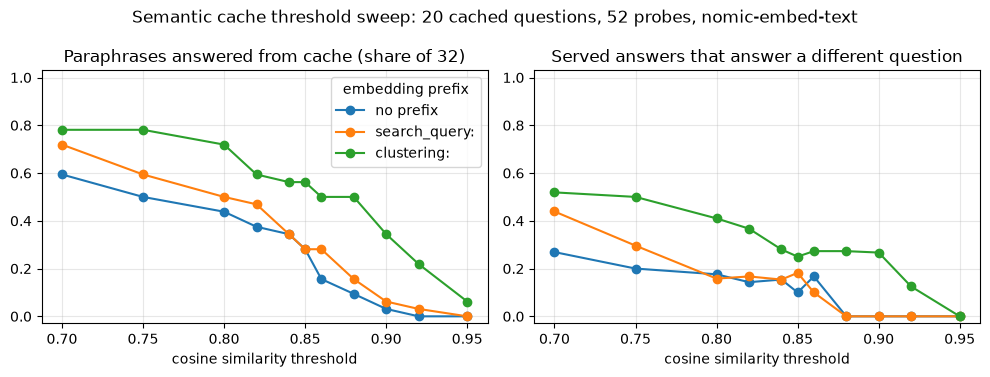

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for name, df in sweeps.items():
    axes[0].plot(df.threshold, df[f"hit rate (of {N_PARA})"], marker="o", label=name)
    axes[1].plot(df.threshold, df["false-hit rate (of served)"], marker="o", label=name)
axes[0].set_title(f"Paraphrases answered from cache (share of {N_PARA})")
axes[1].set_title("Served answers that answer a different question")
for ax in axes:
    ax.set_xlabel("cosine similarity threshold")
    ax.grid(alpha=0.3)
    ax.set_ylim(-0.03, 1.03)
axes[0].legend(title="embedding prefix")
fig.suptitle(f"Semantic cache threshold sweep: {len(SEEDS)} cached questions, {len(PROBES)} probes, nomic-embed-text")
fig.tight_layout()
fig.savefig(IMAGES / "15-semcache-sweep.png", dpi=150)
plt.show()

### A second opinion before serving

No single threshold gives both a useful hit rate and zero false hits. So we split the decision: retrieve a candidate with a *loose* threshold (0.75), then ask `fast` whether the cached question and the new one really have the same answer. The confirmation prompt is generic; it doesn't list our near-miss patterns.

In [13]:
CONFIRM_PROMPT = """Two questions sent to an online shop's customer-support assistant.

Question A (already answered): {cached}
Question B (new): {new}

Would the correct answer to A also be a complete and correct answer to B? A related topic is
not enough: B must ask for the same information as A."""
CONFIRM_SCHEMA = {"type": "json_schema", "json_schema": {"name": "same", "strict": True, "schema": {
    "type": "object", "properties": {"same": {"type": "boolean"}},
    "required": ["same"], "additionalProperties": False}}}
RETRIEVE_AT = 0.75


def confirm(model: str, cached_q: str, new_q: str):
    c = chat(gw, model, [{"role": "user", "content": CONFIRM_PROMPT.format(cached=cached_q, new=new_q)}],
             400, response_format=CONFIRM_SCHEMA, extra_body=gateway.NO_CACHE)
    if model != "local":
        LEDGER.append(("semantic cache", c))
    try:
        return json.loads(c.text)["same"] is True, c
    except (json.JSONDecodeError, KeyError, TypeError):
        return False, c                      # unparseable: don't serve


two_stage = {}
for model in ["fast"] + (["local"] if RUN_LOCAL else []):
    rows = []
    for _, row in near.iterrows():
        same, c = confirm(model, SEEDS[row.nearest], row.probe) if row.similarity >= RETRIEVE_AT else (False, None)
        rows.append({"probe": row.probe, "served": same, "right": row.nearest in row.ok,
                     "should_hit": bool(row.ok), "confirm_s": c.latency_s if c else None,
                     "confirm_usd": c.cost_usd if c else 0.0})
    df = pd.DataFrame(rows)
    two_stage[model] = df
    s = df[df.served]
    print(f"retrieve at {RETRIEVE_AT} + {model} confirms: served {len(s)}, correct {s.right.sum()}, "
          f"false hits {(~s.right).sum()}, hit rate {s.right.sum() / N_PARA:.3f}; "
          f"{df.confirm_s.notna().sum()} confirmation calls, median {df.confirm_s.median() * 1000:.0f} ms, "
          f"${df.confirm_usd.sum():.6f} total")
    print("   false hits:", s[~s.right].probe.tolist())

retrieve at 0.75 + fast confirms: served 8, correct 8, false hits 0, hit rate 0.250; 20 confirmation calls, median 3059 ms, $0.000947 total
   false hits: []


retrieve at 0.75 + local confirms: served 13, correct 12, false hits 1, hit rate 0.375; 20 confirmation calls, median 380 ms, $0.000000 total
   false hits: ["Where's my package?"]


In [14]:
# For comparison: how long does a fresh answer take, without any cache?
fresh = {}
for model in ["fast"] + (["local"] if RUN_LOCAL else []):
    lat = []
    for p in PROBES[:5]:
        c = chat(gw, model, [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": p["q"]}],
                 400, extra_body=gateway.NO_CACHE)
        if model != "local":
            LEDGER.append(("semantic cache", c))
        lat.append(c.latency_s)
    fresh[model] = statistics.median(lat)
    print(f"fresh answer from {model}: median {fresh[model] * 1000:.0f} ms over 5 questions")

fresh answer from fast: median 1195 ms over 5 questions


fresh answer from local: median 1413 ms over 5 questions


Finally, what must never go into a shared cache: follow-ups (they mean nothing without the conversation) and anything personal.

In [15]:
for msgs in [
    [{"role": "user", "content": "How long do refunds take?"}],
    [{"role": "user", "content": "Where is order #48213?"}],
    [{"role": "user", "content": "I'm ana@example.com, did my refund go through?"}],
    [{"role": "user", "content": "Can I return shoes?"}, {"role": "assistant", "content": "Yes, within 30 days."},
     {"role": "user", "content": "And for VIPs?"}],
]:
    print(f"{semcache.is_cacheable(msgs)!s:5} | {msgs[-1]['content']}")

True  | How long do refunds take?
False | Where is order #48213?
False | I'm ana@example.com, did my refund go through?
False | And for VIPs?


## Iteration 6: provider prompt caching

Providers cache the *prefix* of a prompt they've just seen and bill those tokens at a fraction of the price. We send a long system prompt (the FAQ plus all 13 policies) with five different short questions, straight to OpenRouter so we see the provider's own bill (`usage.cost`) and `prompt_tokens_details.cached_tokens`.

Five variants: gpt-6-luna as is (OpenAI caches automatically), gpt-6-luna with a request id at the top of the system prompt (a classic cache buster), claude-haiku-5.5 with and without an explicit `cache_control` breakpoint, and claude-sonnet-5.5 with one.

In [16]:
docs_dir = FAQ_PATH.parent
LONG_DOCS = "\n\n".join(p.read_text() for p in [FAQ_PATH, *sorted((docs_dir / "policies").glob("*.md"))])
# A tag unique to this notebook run, at the very top: every run starts with a cold cache (a
# re-run within the cache TTL would otherwise find the prefix still warm), and within the run
# the prefix is identical for all five calls.
RUN_TAG = f"Document snapshot {time.time_ns()}"
LONG_SYSTEM = (f"{RUN_TAG}\nYou are ShopFlow's support assistant. Answer only from the documents below, "
               "in at most two sentences.\n\n" + LONG_DOCS)
PC_QUESTIONS = ["How long do refunds take?", "Which carriers do you use?",
                "Is express shipping free for VIP members?", "Do you accept PayPal?",
                "How do I delete my account?"]
or_client = chat_client(max_retries=0)


def system_message(text: str, breakpoint: bool) -> dict:
    if not breakpoint:
        return {"role": "system", "content": text}
    # Anthropic caches only up to an explicit breakpoint; OpenRouter passes it through.
    return {"role": "system", "content": [{"type": "text", "text": text,
                                           "cache_control": {"type": "ephemeral"}}]}


def caching_run(label: str, model: str, breakpoint: bool, bust: bool = False) -> list[dict]:
    rows = []
    for i, q in enumerate(PC_QUESTIONS):
        text = f"Request id: {time.time_ns()}\n\n{LONG_SYSTEM}" if bust else LONG_SYSTEM
        c = chat(or_client, model, [system_message(text, breakpoint), {"role": "user", "content": q}],
                 max_tokens=300, reasoning_effort="low")   # Sonnet 5.5 can't turn reasoning off
        LEDGER.append(("prompt caching", c))
        rows.append({"variant": label, "call": i + 1, "prompt_tokens": c.prompt_tokens,
                     "cache_write": c.cache_write_tokens, "cached": c.cached_tokens,
                     "cost_usd": c.cost_usd, "latency_s": round(c.latency_s, 2)})
    return rows


pc_rows = []
for label, model, bp, bust in [
    ("gpt-6-luna (automatic)", "openai/gpt-6-luna", False, False),
    ("gpt-6-luna + request id on top", "openai/gpt-6-luna", False, True),
    ("claude-haiku-5.5, no breakpoint", "anthropic/claude-haiku-5.5", False, False),
    ("claude-haiku-5.5 + cache_control", "anthropic/claude-haiku-5.5", True, False),
    ("claude-sonnet-5.5 + cache_control", "anthropic/claude-sonnet-5.5", True, False),
]:
    pc_rows += caching_run(label, model, bp, bust)
pc = pd.DataFrame(pc_rows)
print(pc.to_string(index=False))

                          variant  call  prompt_tokens  cache_write  cached  cost_usd  latency_s
           gpt-6-luna (automatic)     1          11140        11137       0  0.001418       1.58
           gpt-6-luna (automatic)     2          11140           10   11127  0.000124       1.23
           gpt-6-luna (automatic)     3          11142           12   11127  0.000124       1.22
           gpt-6-luna (automatic)     4          11140           10   11127  0.000119       1.76
           gpt-6-luna (automatic)     5          11141           11   11127  0.000133       1.75
   gpt-6-luna + request id on top     1          11152        11149       0  0.001420       1.68
   gpt-6-luna + request id on top     2          11152        11149       0  0.001406       1.09
   gpt-6-luna + request id on top     3          11154        11151       0  0.001405       1.99
   gpt-6-luna + request id on top     4          11152        11149       0  0.001400       1.09
   gpt-6-luna + request id on 

In [17]:
def summarize(g):
    first, warm = g.iloc[0], g.iloc[1:]
    return pd.Series({"prompt tokens": int(first.prompt_tokens),
                      "1st call $": first.cost_usd, "calls 2-5 avg $": warm.cost_usd.mean(),
                      "warm cached share": warm.cached.sum() / warm.prompt_tokens.sum(),
                      "1st call s": first.latency_s, "calls 2-5 avg s": warm.latency_s.mean()})


pc_summary = pc.groupby("variant", sort=False).apply(summarize, include_groups=False)
pc_summary["warm saving"] = 1 - pc_summary["calls 2-5 avg $"] / pc_summary["1st call $"]
print(pc_summary.round({"1st call $": 6, "calls 2-5 avg $": 6, "warm cached share": 3,
                        "1st call s": 2, "calls 2-5 avg s": 2, "warm saving": 3}).to_string())

                                   prompt tokens  1st call $  calls 2-5 avg $  warm cached share  1st call s  calls 2-5 avg s  warm saving
variant                                                                                                                                   
gpt-6-luna (automatic)                   11140.0    0.001418         0.000125              0.999        1.58             1.49        0.912
gpt-6-luna + request id on top           11152.0    0.001420         0.001406              0.000        1.68             1.34        0.010
claude-haiku-5.5, no breakpoint          16967.0    0.001738         0.001727              0.000        1.98             1.48        0.006
claude-haiku-5.5 + cache_control         16967.0    0.002161         0.000201              0.999        1.27             1.09        0.907
claude-sonnet-5.5 + cache_control        16967.0    0.043170         0.002300              0.999        1.49             1.31        0.947


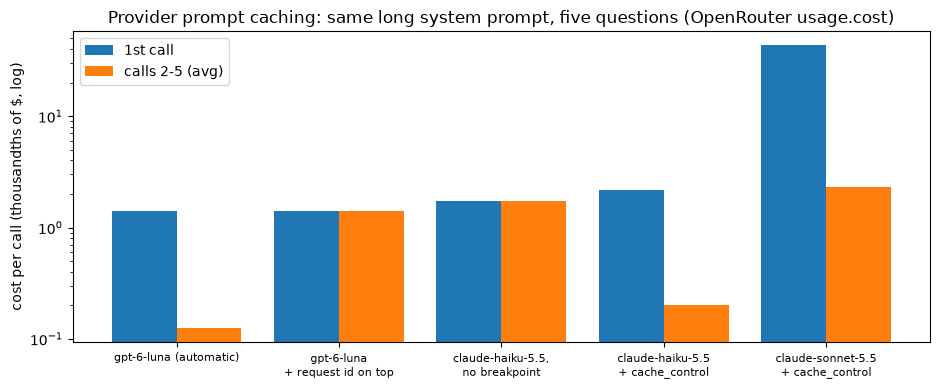

In [18]:
fig, ax = plt.subplots(figsize=(9.5, 4))
labels = list(pc_summary.index)
x = range(len(labels))
ax.bar([i - 0.2 for i in x], pc_summary["1st call $"] * 1000, width=0.4, label="1st call")
ax.bar([i + 0.2 for i in x], pc_summary["calls 2-5 avg $"] * 1000, width=0.4, label="calls 2-5 (avg)")
ax.set_xticks(list(x), [lbl.replace(" + ", "\n+ ").replace(", ", ",\n") for lbl in labels], fontsize=8)
ax.set_ylabel("cost per call (thousandths of $, log)")
ax.set_yscale("log")
ax.set_title("Provider prompt caching: same long system prompt, five questions (OpenRouter usage.cost)")
ax.legend()
fig.tight_layout()
fig.savefig(IMAGES / "15-prompt-caching.png", dpi=150)
plt.show()

## Iteration 7: a cheap → strong cascade with a verifier

40 customer questions with reference answers written from the FAQ ([`data/cascade_questions.yaml`](data/cascade_questions.yaml)): 15 direct look-ups, 13 that combine two FAQ entries or need a small inference, 8 the FAQ doesn't cover (the bot must say so), 4 off-topic or manipulative.

Every strategy runs through the gateway with the Chapter 1 system prompt, marked as a cacheable prefix. A cascade answers with a cheap tier, asks a cheap verifier whether the draft is supported by the FAQ and actually answers the question, and escalates to `smart` only if the check fails. `smart` (Sonnet) grades every final answer against the reference *and* the FAQ.

The eval lives in [`eval/run_cascade.py`](eval/run_cascade.py) and writes [`eval/results/cascade.json`](eval/results/cascade.json); this notebook runs it only if that file is missing, so re-executing the notebook doesn't pay for the eval twice. Each distinct model call runs once and is replayed for every strategy that would make the same call, so the eval pays for each call once. Each strategy's cost and latency still count every call it makes.

`fast-alt` is `anthropic/claude-haiku-5.5`: same price as `fast`, different model family. Does a verifier from another family catch more of `fast`'s mistakes than `fast` checking itself? With `RUN_LOCAL=1` (and the results file deleted) the table also gets `local only` and `local → smart (local verifies)`.

In [19]:
sys.path.insert(0, str(Path.cwd() / "eval"))
import run_cascade

if not run_cascade.RESULTS.exists():
    run_cascade.run(local=RUN_LOCAL)
cas = json.loads(run_cascade.RESULTS.read_text())
res = pd.DataFrame(cas["rows"])
calls = pd.DataFrame(cas["calls"])
print(f"eval run {cas['date']}: {len(res)} strategy × question rows, {cas['answer_calls']} distinct answer/verify "
      f"calls ({cas['answer_seconds']:.0f} s), {cas['graded_answers']} answers graded")
print(f"eval cost: ${cas['hosted_cost_usd']:.4f} total, of which judge ${cas['judge_cost_usd']:.4f}")
by_model = calls.groupby("model")[["prompt_tokens", "cached_tokens", "cost_usd"]].sum()
by_model["cached share"] = (by_model.cached_tokens / by_model.prompt_tokens).round(3)
print(by_model.to_string())

eval run 2026-11-09: 240 strategy × question rows, 240 distinct answer/verify calls (456 s), 118 answers graded
eval cost: $0.2564 total, of which judge $0.1933
          prompt_tokens  cached_tokens  cost_usd  cached share
model                                                         
fast              93220          87984  0.004850         0.944
fast-alt          77946          68968  0.004633         0.885
local             94813          89016  0.000000         0.939
smart            317150         278343  0.246927         0.878


In [20]:
def strategy_row(g):
    by_kind = g.groupby("kind")["pass"].agg(lambda s: f"{s.sum()}/{len(s)}")
    return pd.Series({
        "pass rate": g["pass"].mean(),
        "direct": by_kind.get("direct"), "combine": by_kind.get("combine"),
        "not covered": by_kind.get("not_covered"), "off topic": by_kind.get("off_topic"),
        "escalated": g.escalated.mean(),
        "$ / 1k questions": g.cost_usd.mean() * 1000,
        "p50 s": g.latency_s.quantile(0.5), "p95 s": g.latency_s.quantile(0.95),
    })


table = res.groupby("strategy", sort=False).apply(strategy_row, include_groups=False)
table["saving vs smart"] = 1 - table["$ / 1k questions"] / table.loc["smart only", "$ / 1k questions"]
print(table.to_string(formatters={"pass rate": "{:.1%}".format, "escalated": "{:.0%}".format,
                                  "$ / 1k questions": "{:.4f}".format, "p50 s": "{:.1f}".format,
                                  "p95 s": "{:.1f}".format, "saving vs smart": "{:.0%}".format}))

                                 pass rate direct combine not covered off topic escalated $ / 1k questions p50 s p95 s saving vs smart
strategy                                                                                                                              
fast only                            92.5%  15/15   12/13         6/8       4/4        0%           0.0423   1.5   4.1             97%
smart only                           97.5%  15/15   12/13         8/8       4/4        0%           1.3407   1.4   2.1              0%
fast → smart (fast verifies)         92.5%  15/15   12/13         6/8       4/4       12%           0.3042   4.9   9.4             77%
fast → smart (fast-alt verifies)     92.5%  15/15   12/13         6/8       4/4        2%           0.1825   2.9   6.6             86%
local only                           55.0%  13/15    5/13         1/8       3/4        0%           0.0000   1.5   2.3            100%
local → smart (local verifies)       57.5%  13/15    5/

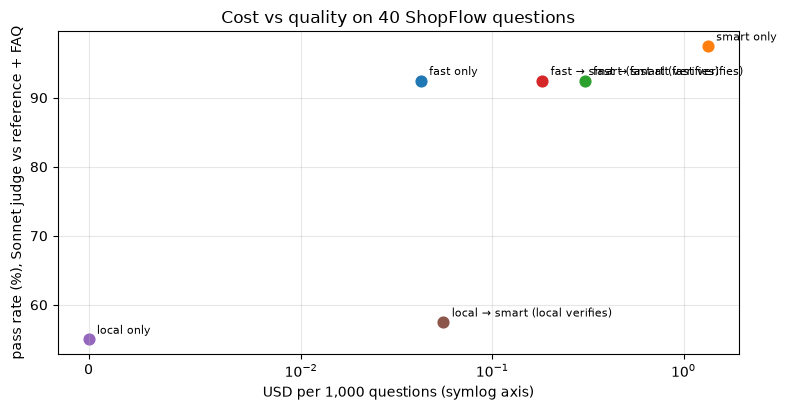

In [21]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for name, row in table.iterrows():
    ax.scatter(row["$ / 1k questions"], row["pass rate"] * 100, s=60)
    ax.annotate(name, (row["$ / 1k questions"], row["pass rate"] * 100), fontsize=8,
                xytext=(6, 4), textcoords="offset points")
ax.set_xscale("symlog", linthresh=0.01)
ax.set_xlabel("USD per 1,000 questions (symlog axis)")
ax.set_ylabel("pass rate (%), Sonnet judge vs reference + FAQ")
ax.set_title(f"Cost vs quality on {res.id.nunique()} ShopFlow questions")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES / "15-cascade-cost-quality.png", dpi=150)
plt.show()

Where did the strategies fail, and what did the verifier say?

In [22]:
for name in cas["strategies"]:
    bad = res[(res.strategy == name) & (~res["pass"])]
    print(f"== {name}: {len(bad)} failures: {bad.id.tolist()}")
for name in ["fast → smart (fast verifies)", "fast → smart (fast-alt verifies)"]:
    bad = res[(res.strategy == name) & (~res["pass"])]
    print(f"\n== {name}")
    for _, row in bad.iterrows():
        print(f"  [{row.id}] by {row.answered_by}: {' '.join(row.answer.split())[:150]!r}\n"
              f"        verifier: {row.verdict!r}\n        judge: {row.judge_reason}")

== fast only: 3 failures: ['c05', 'n03', 'n07']
== smart only: 1 failures: ['c08']
== fast → smart (fast verifies): 3 failures: ['c05', 'n03', 'n07']
== fast → smart (fast-alt verifies): 3 failures: ['c05', 'n03', 'n07']
== local only: 18 failures: ['d07', 'd14', 'c01', 'c03', 'c05', 'c06', 'c07', 'c08', 'c11', 'c13', 'n01', 'n02', 'n03', 'n04', 'n05', 'n06', 'n08', 'o04']
== local → smart (local verifies): 17 failures: ['d07', 'd14', 'c01', 'c03', 'c05', 'c06', 'c07', 'c08', 'c11', 'c13', 'n01', 'n02', 'n03', 'n04', 'n05', 'n06', 'n08']

== fast → smart (fast verifies)
  [c05] by fast: 'Express shipping to New York takes 1–2 business days. Since you’d order after the 2 PM same-day shipping cutoff, the FAQ doesn’t specify when it would'
        verifier: 'The FAQ gives a 1–2 business-day express timeframe and same-day shipping only for orders placed before 2 PM, so the exact arrival date cannot be determined.'
        judge: The answer omits the key fact that an order placed after the 

## What this notebook spent

Every hosted call in this notebook went into `LEDGER`. Calls through the gateway carry the gateway's cost header (computed from the prices in `config.yaml`); direct OpenRouter calls carry OpenRouter's `usage.cost`. The cascade eval's cost is recorded in its results file. The OpenRouter key is shared with other chapters' runs, so the key-level difference can include their traffic.

In [23]:
spend = pd.DataFrame([{"section": s, "model": c.model, "cost_usd": c.cost_usd} for s, c in LEDGER])
print(spend.groupby("section", sort=False).cost_usd.agg(["count", "sum"]).round(6).to_string())
print(f"\nnotebook ledger: ${spend.cost_usd.sum():.4f}; cascade eval ({cas['date']}): "
      f"${cas['hosted_cost_usd']:.4f}; together ${spend.cost_usd.sum() + cas['hosted_cost_usd']:.4f}")
time.sleep(30)                       # OpenRouter's key usage lags the calls by some seconds
usage_after = openrouter_usage()
print(f"OpenRouter key usage: before ${USAGE_BEFORE:.4f}, after ${usage_after:.4f}, "
      f"difference ${usage_after - USAGE_BEFORE:.4f} (key-wide)")
db.close()

                count       sum
section                        
v0                  3  0.000100
gateway             2  0.000099
budget              1  0.000164
exact cache         3  0.000072
semantic cache     45  0.001746
prompt caching     25  0.072944

notebook ledger: $0.0751; cascade eval (2026-11-09): $0.2564; together $0.3315


OpenRouter key usage: before $157.5881, after $157.6163, difference $0.0282 (key-wide)
